In [19]:
# Libraries (the same ones used in the module examples)
import pandas as pd                 # tables (DataFrames)
import numpy as np                  # numerical operations
import matplotlib.pyplot as plt     # static charts
import seaborn as sns               # heatmap
import plotly.express as px         # interactive charts
import ipywidgets as widgets        # dashboard filters
from IPython.display import display

%matplotlib inline

In [20]:
# LOAD THE DATA
# The dataset is not in the GitHub repository. Put Online_Retail.xlsx in the same folder as this notebook.
# InvoiceNo and StockCode are read as text because some values contain letters (e.g. C536379, 85123A).
raw = pd.read_excel("Online_Retail.xlsx", dtype={"InvoiceNo": str, "StockCode": str})
print(raw.shape)
raw.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


### 2.1 Investigating invalid and suspicious records

Following the distinction between **visible errors** (blank cells / NaN) and **obscure errors** (values that exist but are invalid, such as a negative quantity or price), I already counted the visible errors above. Below I investigate the obscure errors step by step, to understand **what** these records are before deciding **how** to treat them.

In [23]:
# STRUCTURE CHECK
# First I look at every column: its data type and how many values are filled in.
# This tells me if pandas read the data correctly and where values are missing.
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [24]:
# FIRST LOOK AT THE NUMBERS
# describe() gives min, max, mean and quartiles. I use it to spot impossible values:
# a sale cannot have a negative quantity or a negative price.
raw[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,"541,909.00","541,909.00"
mean,9.55,4.61
std,218.08,96.76
min,"-80,995.00","-11,062.06"
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,"80,995.00","38,970.00"


The summary already shows problems: **negative quantities and prices**, and extreme values (±80,995 units, unit price of £38,970) that are far from the median (3 units at £2.08). These are investigated below.

In [25]:
# MISSING VALUES
# isna() marks empty cells as True. sum() counts them, mean() gives the proportion.
# I show the percentage because 1,000 missing values means little without knowing the total.
missing = pd.DataFrame({"missing": raw.isna().sum(),
                        "% of rows": raw.isna().mean() * 100})
missing[missing["missing"] > 0]

,missing,% of rows
Description,1454,0.27
CustomerID,135080,24.93


### 2.1 Investigating invalid and suspicious records

The summary statistics showed negative quantities, negative prices and extreme values. Below I investigate each problem step by step, to understand **what** these records are before deciding **how** to treat them.

In [26]:
# DUPLICATES
# A duplicate is a row identical in every column: same invoice, product, quantity,
# price, time and customer. That is the same sale recorded twice, so it would double-count revenue.
print("Exact duplicate rows:", raw.duplicated().sum())

# keep=False shows BOTH copies, so I can see with my own eyes that they are identical
raw[raw.duplicated(keep=False)].sort_values(["InvoiceNo", "StockCode"]).head(6)

Exact duplicate rows: 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,"17,908.00",United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,"17,908.00",United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,"17,908.00",United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,"17,908.00",United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,"17,908.00",United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,"17,908.00",United Kingdom


In [27]:
# INVOICE NUMBERS
# Invoice numbers should be numbers. I check the FIRST character of every invoice number
# (str[0]) and count them, to find out if some start with a letter.
raw["InvoiceNo"].str[0].value_counts()

InvoiceNo
5    532618
C      9288
A         3
Name: count, dtype: int64

In [28]:
# PREFIX "A" – only 3 rows, so I can look at all of them
raw[raw["InvoiceNo"].str.startswith("A")]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,"11,062.06",NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.06",NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.06",NaN,United Kingdom


In [34]:
# Do the "C" invoices mean cancellations? If yes, all of them should have a NEGATIVE quantity.
is_c = raw["InvoiceNo"].str.startswith("C")
cancelled = raw[is_c]
print("Rows with a C invoice:", len(cancelled))
print("  with negative quantity:", (cancelled["Quantity"] < 0).sum())
print("  with positive quantity:", (cancelled["Quantity"] > 0).sum())

# And are there negative quantities on NORMAL invoices too?  (~ means NOT)
normal = raw[~is_c]
print("Normal invoices with quantity <= 0:", (normal["Quantity"] <= 0).sum())

Rows with a C invoice: 9288
  with negative quantity: 9288
  with positive quantity: 0
Normal invoices with quantity <= 0: 1336


In [35]:
# NEGATIVE QUANTITY ON A NORMAL INVOICE
# These rows are not cancellations, so what are they? I check their price, customer and description.
odd_qty = raw[(raw["Quantity"] <= 0) & ~is_c]          # ~ means NOT
print("Rows:", len(odd_qty))
print("Unit prices found:", odd_qty["UnitPrice"].unique())
print("Rows with a customer:", odd_qty["CustomerID"].notna().sum())
odd_qty["Description"].value_counts().head(10)

Rows: 1336
Unit prices found: [0.]
Rows with a customer: 0


Description
check                     120
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
??                          7
damages?                    5
Name: count, dtype: int64

In [36]:
# ZERO OR NEGATIVE PRICE
# A product sold for £0 is not a sale. I check what these rows are.
odd_price = raw[raw["UnitPrice"] <= 0]
print("Rows with price <= 0:", len(odd_price))
print("Negative prices:", (odd_price["UnitPrice"] < 0).sum())
print("Rows with a customer:", odd_price["CustomerID"].notna().sum())
odd_price["Description"].value_counts(dropna=False).head(10)

Rows with price <= 0: 2517
Negative prices: 2
Rows with a customer: 40


Description
NaN                      1454
check                     159
?                          47
damages                    45
damaged                    43
found                      25
sold as set on dotcom      20
adjustment                 16
Damaged                    14
thrown away                 9
Name: count, dtype: int64

In [37]:
# PRODUCT CODES
# Looking at raw.head(), product codes look like "71053" or "85123A": they START with 5 digits.
# str[:5] takes the first 5 characters and isdigit() checks if they are all numbers.
normal_code = raw["StockCode"].str[:5].str.isdigit()
print("Share of rows with a normal product code:", round(normal_code.mean() * 100, 1), "%")

# Now I look at the codes that do NOT follow this pattern
odd = raw[~normal_code]
odd["StockCode"].value_counts()

Share of rows with a normal product code: 99.4 %


StockCode
POST            1256
DOT              710
M                571
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
DCGSSBOY          11
gift_0001_20      10
gift_0001_10       9
gift_0001_30       8
DCGS0003           5
gift_0001_50       4
PADS               4
gift_0001_40       3
B                  3
DCGS0070           2
DCGS0076           2
DCGS0069           2
m                  1
DCGS0055           1
DCGS0057           1
DCGS0074           1
DCGS0072           1
DCGS0004           1
DCGS0073           1
DCGS0068           1
DCGS0071           1
DCGS0066P          1
DCGS0067           1
Name: count, dtype: int64

In [38]:
# What are these codes? I show one description for each code (drop_duplicates keeps the first row of each).
odd.drop_duplicates("StockCode")[["StockCode", "Description"]]

,StockCode,Description
45,POST,POSTAGE
141,D,Discount
1423,C2,CARRIAGE
1814,DOT,DOTCOM POSTAGE
2239,M,Manual
4406,BANK CHARGES,Bank Charges
14436,S,SAMPLES
14514,AMAZONFEE,AMAZON FEE
21326,DCGS0076,SUNJAR LED NIGHT NIGHT LIGHT
24906,DCGS0003,BOXED GLASS ASHTRAY


In [39]:
# OUTLIERS
# The maximum quantity was 80,995 while the median is 3. I look at the biggest orders.
cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "InvoiceDate"]
top = raw[raw["Quantity"] > 0].nlargest(5, "Quantity")[cols]
top

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"16,446.00",2011-12-09 09:15:00
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"12,346.00",2011-01-18 10:01:00
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,"13,256.00",2011-11-25 15:57:00
74614,542504,37413,NaN,5568,0.00,NaN,2011-01-28 12:03:00
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,"12,901.00",2011-10-27 12:26:00


Looking at the five biggest orders: the 3rd and 4th have a price of £0, so they will be removed later with the other zero-price rows. The 5th (4,800 gliders at £0.21) looks like a normal big wholesale order, so I will keep it. Next, I check if the two biggest orders are real.

In [40]:
# Is the biggest order real? I search for every row with the same customer AND the same product.
biggest = top.iloc[0]
raw[(raw["CustomerID"] == biggest["CustomerID"]) &
    (raw["StockCode"] == biggest["StockCode"])][cols]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"16,446.00",2011-12-09 09:15:00
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,"16,446.00",2011-12-09 09:27:00


In [41]:
# COUNTRIES AND TIME PERIOD
# I list all countries to check if the names are clear and consistent.
print("Number of countries:", raw["Country"].nunique())
print(sorted(raw["Country"].unique()))
print("\nFirst invoice:", raw["InvoiceDate"].min())
print("Last invoice: ", raw["InvoiceDate"].max())

Number of countries: 38
['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'Channel Islands', 'Cyprus', 'Czech Republic', 'Denmark', 'EIRE', 'European Community', 'Finland', 'France', 'Germany', 'Greece', 'Hong Kong', 'Iceland', 'Israel', 'Italy', 'Japan', 'Lebanon', 'Lithuania', 'Malta', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'RSA', 'Saudi Arabia', 'Singapore', 'Spain', 'Sweden', 'Switzerland', 'USA', 'United Arab Emirates', 'United Kingdom', 'Unspecified']

First invoice: 2010-12-01 08:26:00
Last invoice:  2011-12-09 12:50:00


**Summary of data-quality findings**

| Issue | What I found | Planned action |
|---|---|---|
| Duplicates | 5,268 identical rows | Remove |
| Cancellations ("C" invoices) | ~9,300 rows, all with negative quantity | Keep apart as returns; also remove the purchase they reverse |
| Bad-debt adjustments ("A" invoices) | 3 accounting rows | Remove |
| Negative quantity, not cancelled | 1,336 rows, price £0, no customer: stock adjustments | Remove |
| Price ≤ £0 | Free items, adjustments, no description | Remove |
| Non-product codes | Postage, fees, manual, discounts, vouchers | Remove; keep DCGS and PADS (real products) |
| Missing CustomerID | ~25% of rows | Decide in cleaning (see Section 3) |
| Huge orders | The two largest were cancelled minutes later | Remove purchase + cancellation |
| Country labels | EIRE, RSA, Unspecified, European Community | Rename the first two; note the others |
| Period | Ends 9 Dec 2011 | Flag December 2011 as a partial month |

## 3. Data cleaning and preparation

In this section I fix the problems I found in Section 2. I do not change the original data (`raw`). I work on a copy called `df`, so I can always go back if I make a mistake. After each step I print how many rows were removed, so it is easy to see what each step did.


In [42]:
# WORKING COPY
# I keep "raw" untouched and clean a copy. If I make a mistake I can always go back to the original.
df = raw.copy()
print("Rows before cleaning:", len(df))

Rows before cleaning: 541909


In [43]:
# STEP 1 – REMOVE DUPLICATES
# Section 2 showed 5,268 rows that are identical in every column: the same sale recorded twice.
# Keeping them would count that revenue twice, so I keep only one copy of each.
before = len(df)
df = df.drop_duplicates()
print("Duplicates removed:", before - len(df))

Duplicates removed: 5268


In [44]:
# STEP 2 – FIX DATA TYPES AND TEXT
# StockCode: upper case, so "m" and "M" become the same code; strip() removes spaces at the ends.
df["StockCode"] = df["StockCode"].str.strip().str.upper()
df["Description"] = df["Description"].str.strip()

# CustomerID was stored as a decimal (17850.0) only because it has missing values.
# "Int64" (capital I) is the pandas integer type that ALLOWS missing values, so 17850.0 becomes 17850.
df["CustomerID"] = df["CustomerID"].astype("Int64")

# InvoiceDate was already read as a date from Excel; to_datetime makes sure it is a real date type
# (needed later to group sales by month, weekday and hour).
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              Int64
Country                object
dtype: object

In [45]:
# STEP 3a – SEPARATE CANCELLATIONS
# Section 2 showed that every "C" invoice has a negative quantity: they are cancellations, not sales.
# I do not just delete them: I keep them in a separate table called "returns" (useful to measure returns),
# and remove them from the sales table.
is_c = df["InvoiceNo"].str.startswith("C")
returns = df[is_c].copy()
df = df[~is_c].copy()
print("Cancellation rows moved to 'returns':", len(returns))
print("Sales rows remaining:", len(df))

Cancellation rows moved to 'returns': 9251
Sales rows remaining: 527390


**Step 3b – Removing purchases that were cancelled**

In Section 2 I found that the biggest order (80,995 units) was cancelled 12 minutes later. If I only delete the cancellation row, the original order stays in the data and counts as £168k of sales that never really happened.

So for each cancellation, I look for the order it cancels. It must have the **same customer, same product and same quantity**, and it must happen **before** the cancellation. Then I remove that order too.

Some customers only returned part of an order (for example 5 out of 12 items). I cannot match these to one exact order, so I leave them in the data. I mention this in the limitations.

In [46]:
# STEP 3b – REMOVE PURCHASES THAT WERE FULLY CANCELLED

# 1) Prepare the cancellations: I only need customer, product, quantity and date.
#    The quantity is negative in a cancellation (-80995), so I make it positive to match the purchase (80995).
c = returns[["CustomerID", "StockCode", "Quantity", "InvoiceDate"]].copy()
c["Quantity"] = -c["Quantity"]
c = c.rename(columns={"InvoiceDate": "CancelDate"})
c = c.dropna(subset=["CustomerID"])          # without a customer I cannot know whose purchase it was

# 2) Merge purchases with cancellations: a row is kept only where customer, product AND quantity are equal.
#    reset_index() keeps the original row number in a column called "index", so I can delete those rows later.
matched = pd.merge(df.reset_index(), c, on=["CustomerID", "StockCode", "Quantity"], how="inner")

# 3) A purchase can only be cancelled AFTER it was made.
matched = matched[matched["InvoiceDate"] <= matched["CancelDate"]]

# 4) If a customer bought the same thing several times, one cancellation must remove only ONE purchase:
#    I keep the most recent purchase before each cancellation.
matched = matched.sort_values("InvoiceDate")
matched = matched.drop_duplicates(subset=["CustomerID", "StockCode", "Quantity", "CancelDate"], keep="last")

# 5) Remove those purchases from the sales table.
before = len(df)
df = df.drop(index=matched["index"].unique())
print("Cancelled purchases removed:", before - len(df))
print("Revenue that was never realised: £", round((matched["Quantity"] * matched["UnitPrice"]).sum()))

Cancelled purchases removed: 2860
Revenue that was never realised: £ 443458


In [47]:
# CHECK: the two huge orders (80,995 and 74,215 units) should be gone now.
df[df["Quantity"] > 70000]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


In [48]:
# STEP 4 – REMOVE STOCK ADJUSTMENTS
# In Section 2 I found 1,336 rows with quantity 0 or less that are NOT cancellations.
# They all had price £0, no customer and notes like "damaged" or "thrown away".
# These are internal stock corrections, not sales, so I remove them.
before = len(df)
df = df[df["Quantity"] > 0]
print("Stock adjustment rows removed:", before - len(df))

Stock adjustment rows removed: 1336


In [49]:
# STEP 5 – REMOVE ROWS WITH PRICE £0 OR LESS
# A product sold for £0 does not bring any money, and the negative prices were "Adjust bad debt" entries.
# None of these are real sales, so I remove them.
before = len(df)
df = df[df["UnitPrice"] > 0]
print("Zero or negative price rows removed:", before - len(df))

Zero or negative price rows removed: 1176


**Step 6 – Removing codes that are not products**

In Section 2 I looked at every product code that does not start with 5 digits. Most of them are not products: postage, bank and Amazon fees, manual entries, discounts, samples, bad debt and gift vouchers. If I keep them, they would appear in the "top products" charts even though they are not things the company sells. A gift voucher is also not a sale yet, because the customer has not chosen a product.

The DCGS codes (party bags, dog collars, lights) and PADS (cushion pads) also have unusual codes, but they are real products, so I keep them.

In [50]:
# STEP 6 – REMOVE CODES THAT ARE NOT PRODUCTS
# This list comes from what I found in Section 2 (the table of unusual codes and their descriptions).
not_products = ["POST", "DOT", "C2",                  # postage and carriage
                "BANK CHARGES", "AMAZONFEE", "CRUK",  # fees and commissions
                "M", "D", "S", "B"]                   # manual, discount, samples, bad debt
# "m" (lower case) is already "M" because of Step 2

is_not_product = df["StockCode"].isin(not_products) | df["StockCode"].str.startswith("GIFT_")   # | means OR
before = len(df)
df = df[~is_not_product]
print("Non-product rows removed:", before - len(df))

Non-product rows removed: 2283


In [51]:
# STEP 7 – MISSING VALUES
# I check again how many missing values are left after the cleaning steps.
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     131387
Country             0
dtype: int64

In [52]:
# How important are the rows without a customer?
no_customer = df["CustomerID"].isnull()
revenue = df["Quantity"] * df["UnitPrice"]
print("Rows without CustomerID:", round(no_customer.mean() * 100, 1), "%")
print("Sales value of these rows:", round(revenue[no_customer].sum() / revenue.sum() * 100, 1), "% of all sales")

Rows without CustomerID: 25.3 %
Sales value of these rows: 15.4 % of all sales


**Decision on missing values**

- **Description:** after Step 5 there are no missing descriptions left. They were all in rows with a price of £0, which I already removed. So I did not need to fill anything.
- **CustomerID:** about 25% of rows (15% of all sales) have no customer. The lecture notes say that removing rows is fine when missing values are rare, but here they are not rare. These are real orders that were paid (maybe from guest customers), so deleting them would make total sales, product and country results too low. I decided to **keep them** and add a column `HasCustomer` (True/False). I only leave them out when I analyse customers, because there I need to know who the customer is.

In [53]:
# Flag: True if the row has a customer, False if not.
# notnull() is the opposite of isnull(), as in the missing data lecture notes.
df["HasCustomer"] = df["CustomerID"].notnull()
df["HasCustomer"].value_counts()

HasCustomer
True     388348
False    131387
Name: count, dtype: int64

In [54]:
# STEP 8 – CLEAR COUNTRY NAMES
# "EIRE" and "RSA" are short codes that a manager may not understand, so I use the full names.
df["Country"] = df["Country"].replace({"EIRE": "Ireland", "RSA": "South Africa"})
returns["Country"] = returns["Country"].replace({"EIRE": "Ireland", "RSA": "South Africa"})

# "Unspecified" and "European Community" are not real countries, but they are real sales, so I keep them.
print("Rows with an unclear country:", df["Country"].isin(["Unspecified", "European Community"]).sum())

Rows with an unclear country: 499


In [55]:
# RESULT OF THE CLEANING
print("Rows at the start:", len(raw))
print("Rows after cleaning:", len(df))
print("Rows kept:", round(len(df) / len(raw) * 100, 1), "%")

Rows at the start: 541909
Rows after cleaning: 519735
Rows kept: 95.9 %


After cleaning I kept about 96% of the rows. The 4% I removed were duplicates, cancellations, stock adjustments, free items and non-product codes. None of them were real sales, so removing them makes the sales figures more accurate.

### Step 9 – Creating new variables

To answer the business questions I need some new columns that are not in the original data:

- **Revenue** = Quantity × UnitPrice. This is how much money each row brought in. It is the most important number for managers.
- **Weekday** and **Hour** – to see on which days and at what time customers buy.
- **Region** – "United Kingdom" or "International". The UK is much bigger than all other countries, so it is useful to compare the two groups.

I also create two smaller tables:
- **orders** – one row per invoice, with the total value of the order.
- **customers** – one row per customer, with how many orders they made and how much they spent.

In [57]:
# STEP 9 – NEW VARIABLES

# Revenue: the money from each row a new column made from two others

df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Time variables taken from the date
df["Weekday"] = df["InvoiceDate"].dt.day_name()    # Monday, Tuesday...
df["Hour"] = df["InvoiceDate"].dt.hour             # 8, 9, 10...

# Region: np.where works like an IF: if the country is the UK -> "United Kingdom", otherwise -> "International"
df["Region"] = np.where(df["Country"] == "United Kingdom", "United Kingdom", "International")

df[["InvoiceDate", "Quantity", "UnitPrice", "Revenue", "Weekday", "Hour", "Country", "Region"]].head()

,InvoiceDate,Quantity,UnitPrice,Revenue,Weekday,Hour,Country,Region
0,2010-12-01 08:26:00,6,2.55,15.30,Wednesday,8,United Kingdom,United Kingdom
1,2010-12-01 08:26:00,6,3.39,20.34,Wednesday,8,United Kingdom,United Kingdom
2,2010-12-01 08:26:00,8,2.75,22.00,Wednesday,8,United Kingdom,United Kingdom
3,2010-12-01 08:26:00,6,3.39,20.34,Wednesday,8,United Kingdom,United Kingdom
4,2010-12-01 08:26:00,6,3.39,20.34,Wednesday,8,United Kingdom,United Kingdom


In [58]:
# ORDERS TABLE – one row per invoice
# Each invoice has many rows (one per product). groupby("InvoiceNo") puts together all rows of the same invoice.
# For each column I choose how to combine the rows:
#   "first" -> date, customer and country are the same in all rows of an invoice, so I take the first one
#   "sum"   -> I add up the units and the revenue of all products in the invoice
orders = df.groupby("InvoiceNo").agg({"InvoiceDate": "first",
                                      "CustomerID": "first",
                                      "Country": "first",
                                      "Region": "first",
                                      "Quantity": "sum",
                                      "Revenue": "sum"})

# Better names: the total quantity of an order is "Units" and its total revenue is "OrderValue"
orders = orders.rename(columns={"Quantity": "Units", "Revenue": "OrderValue"}).reset_index()
print("Number of orders:", len(orders))
orders.head()

Number of orders: 19648


,InvoiceNo,InvoiceDate,CustomerID,Country,Region,Units,OrderValue
0,536365,2010-12-01 08:26:00,17850,United Kingdom,United Kingdom,40,139.12
1,536366,2010-12-01 08:28:00,17850,United Kingdom,United Kingdom,12,22.20
2,536367,2010-12-01 08:34:00,13047,United Kingdom,United Kingdom,83,278.73
3,536368,2010-12-01 08:34:00,13047,United Kingdom,United Kingdom,15,70.05
4,536369,2010-12-01 08:35:00,13047,United Kingdom,United Kingdom,3,17.85


In [59]:
# CUSTOMERS TABLE – one row per customer
# Only rows WITH a customer (HasCustomer = True), because without an ID I cannot know who bought.
#   "nunique" -> counts how many DIFFERENT invoices the customer has = number of orders
#   "sum"     -> total money the customer spent
customers = df[df["HasCustomer"]].groupby("CustomerID").agg({"InvoiceNo": "nunique",
                                                             "Revenue": "sum",
                                                             "Country": "first",
                                                             "Region": "first"})
customers = customers.rename(columns={"InvoiceNo": "Orders", "Revenue": "Spend"}).reset_index()
print("Number of customers:", len(customers))
customers.head()

Number of customers: 4324


,CustomerID,Orders,Spend,Country,Region
0,12347,7,"4,310.00",Iceland,International
1,12348,4,"1,437.24",Finland,International
2,12349,1,"1,457.55",Italy,International
3,12350,1,294.40,Norway,International
4,12352,6,"1,265.41",Norway,International


### Step 10 – Checking outliers

In Section 2 I removed the outliers that were mistakes (orders that were cancelled). Now I check if there are still very big orders in the clean data.

I use the **IQR rule**: a value is an outlier if it is bigger than Q3 + 1.5 × IQR, where IQR = Q3 − Q1 (the range of the middle 50% of orders).

In [61]:
# OUTLIERS IN ORDER VALUE (IQR rule)
q1 = orders["OrderValue"].quantile(0.25)    # 25% of orders are below this value
q3 = orders["OrderValue"].quantile(0.75)    # 75% of orders are below this value
iqr = q3 - q1                               # range of the middle 50% of orders
upper_limit = q3 + 1.5 * iqr

is_outlier = orders["OrderValue"] > upper_limit
print("Upper limit: £", round(upper_limit))
print("Orders above the limit:", is_outlier.sum(), "=", round(is_outlier.mean() * 100, 1), "% of orders")
print("Their share of total sales:",
      round(orders.loc[is_outlier, "OrderValue"].sum() / orders["OrderValue"].sum() * 100, 1), "%")

Upper limit: £ 972
Orders above the limit: 1780 = 9.1 % of orders
Their share of total sales: 45.5 %


**Decision on outliers**

About 9% of orders are outliers by the IQR rule, but together they make almost half (45%) of all sales. This company is a **wholesaler**, so big orders are normal: they are its most important customers, not mistakes. The biggest orders left (up to about £53k) have no cancellation, so they look real.

So I **keep** these orders. Removing them would hide the most valuable part of the business. Instead, in the charts I will use the **median** (which is not affected by very big values) and a **log scale** when the values are very spread out.

## 4. Exploratory Data Analysis (EDA)

Now that the data is clean, I explore it to answer the business questions. I start with some key numbers and descriptive statistics, and then I use charts to look at sales over time, products, customers and countries.

### 4.1 Key numbers

In [62]:
# KEY NUMBERS (KPIs) – the first things a manager wants to know
total_revenue = df["Revenue"].sum()
uk_revenue = df[df["Region"] == "United Kingdom"]["Revenue"].sum()

print("Total revenue:          £", round(total_revenue))
print("Number of orders:        ", len(orders))
print("Number of customers:     ", len(customers))
print("Number of products:      ", df["StockCode"].nunique())
print("Number of countries:     ", df["Country"].nunique())
print("Average order value:    £", round(orders["OrderValue"].mean(), 2))
print("Median order value:     £", round(orders["OrderValue"].median(), 2))
print("UK share of revenue:     ", round(uk_revenue / total_revenue * 100, 1), "%")
print("Cancelled rows vs sales: ", round(len(returns) / len(df) * 100, 1), "%")

Total revenue:          £ 9823459
Number of orders:         19648
Number of customers:      4324
Number of products:       3794
Number of countries:      38
Average order value:    £ 499.97
Median order value:     £ 301.19
UK share of revenue:      84.7 %
Cancelled rows vs sales:  1.8 %


**What these numbers show:**

- In one year the company sold about **£9.8 million** in **19,648 orders** to **4,324 known customers** in **38 countries**.
- The **UK brings almost 85%** of all revenue, so the company depends a lot on its home market.
- The **average order (£500) is much higher than the median order (£301)**. This means a few very big orders pull the average up. So the median is a better way to describe a "typical" order.
- Only about **1.8%** of rows are cancellations, so returns are not a big problem for this business.

### 4.2 Descriptive statistics

In [64]:
# DESCRIPTIVE STATISTICS of the main numbers
# I put the describe() of each variable side by side in one table, so they are easy to compare.
stats = pd.DataFrame({"Quantity per row": df["Quantity"].describe(),
                      "Unit price (£)": df["UnitPrice"].describe(),
                      "Order value (£)": orders["OrderValue"].describe(),
                      "Orders per customer": customers["Orders"].describe(),
                      "Spend per customer (£)": customers["Spend"].describe()})
stats.round(2)

,Quantity per row,Unit price (£),Order value (£),Orders per customer,Spend per customer (£)
count,"519,735.00","519,735.00","19,648.00","4,324.00","4,324.00"
mean,10.27,3.26,499.97,4.23,"1,922.63"
std,37.13,4.18,"1,132.88",7.57,"8,314.16"
min,1.00,0.00,0.38,1.00,2.90
25%,1.00,1.25,151.20,1.00,301.23
50%,4.00,2.08,301.18,2.00,656.43
75%,11.00,4.13,479.50,5.00,"1,615.04"
max,"4,800.00",649.50,"52,940.94",203.00,"278,742.02"


**What the statistics show:**

In every variable the **mean is much bigger than the median**, and the maximum is very far from the 75% value. This means the data is **right-skewed**: most orders and customers are small, and a few are very big.

For example, half of the customers made 2 orders or less, but one customer made 203. Half of the customers spent less than £656, but the biggest customer spent almost £279k.

Because of this, in the charts I use the **median** to describe what is "typical", and a **log scale** when the values are very spread out.

In [66]:
# UK vs INTERNATIONAL ORDERS – are they different?
# groupby("Region") splits the orders into the two groups; then I calculate count, mean and median for each.
orders.groupby("Region")["OrderValue"].agg(["count", "mean", "median"]).round(2)

,count,mean,median
Region,,,
International,1856,808.99,384.39
United Kingdom,17792,467.74,296.11


**UK vs International:** the UK has almost 10 times more orders, but **international orders are bigger** (median £384 vs £296). This makes sense: it is only worth paying for international shipping when the order is big. I look at this again in the country charts.

### 4.3 Sales over time

#### Chart 1 – Line chart: monthly revenue and number of orders

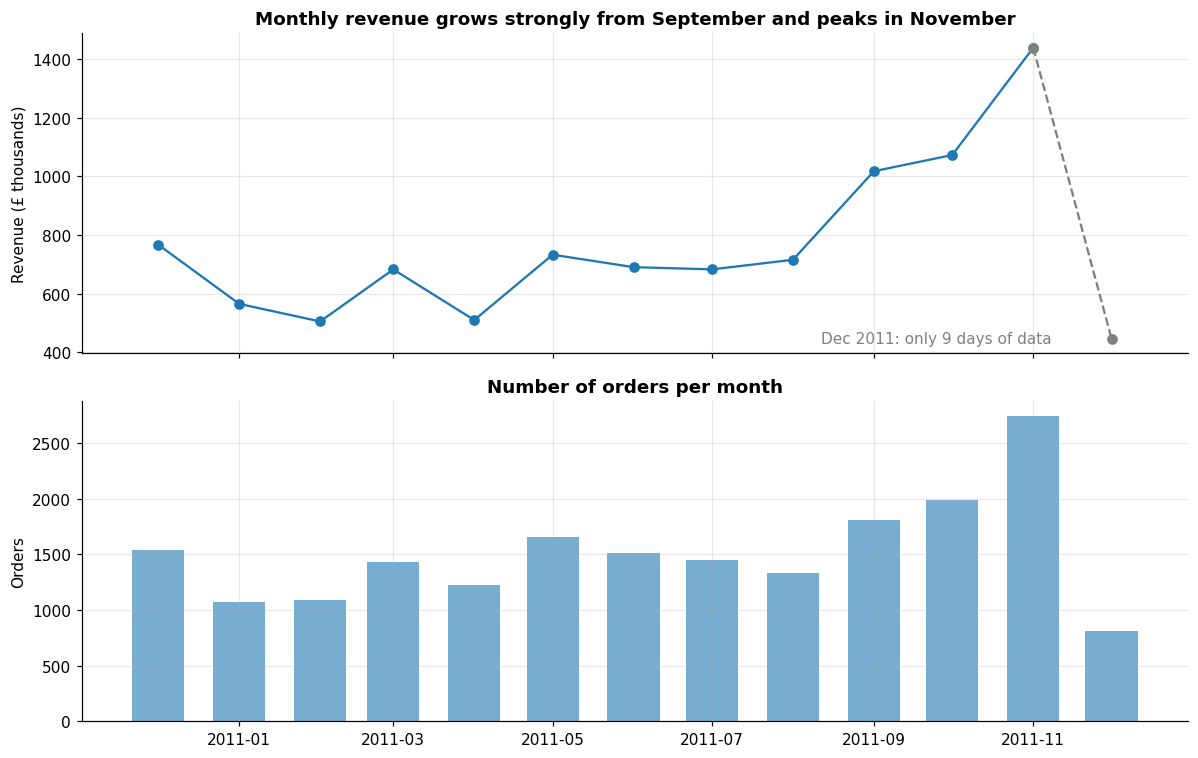

In [67]:
# MONTHLY REVENUE AND ORDERS
# resample() groups the data by time period, like in the Tesla example.
# It needs the date as the index, so I use set_index("InvoiceDate") first.
# "MS" means "Month Start": each month is labelled with its first day (e.g. 2011-01-01).
monthly_revenue = df.set_index("InvoiceDate")["Revenue"].resample("MS").sum()
monthly_orders = orders.set_index("InvoiceDate")["InvoiceNo"].resample("MS").count()

# Two charts, one above the other, sharing the same time axis (sharex=True)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Top chart: revenue in £ thousands (divided by 1000 so the axis is easy to read)
# December 2011 has only 9 days of data, so I draw it grey and dashed so nobody thinks sales crashed.
ax1.plot(monthly_revenue.index[:-1], monthly_revenue.values[:-1] / 1000, marker="o", color="tab:blue")
ax1.plot(monthly_revenue.index[-2:], monthly_revenue.values[-2:] / 1000, marker="o", color="grey", linestyle="--")
ax1.annotate("Dec 2011: only 9 days of data",
             xy=(monthly_revenue.index[-1], monthly_revenue.values[-1] / 1000),
             xytext=(-190, 0), textcoords="offset points", color="grey", va="center")
ax1.set_title("Monthly revenue grows strongly from September and peaks in November")
ax1.set_ylabel("Revenue (£ thousands)")
ax1.grid(alpha=0.3)

# Bottom chart: number of orders per month
ax2.bar(monthly_orders.index, monthly_orders.values, width=20, color="tab:blue", alpha=0.6)
ax2.set_title("Number of orders per month")
ax2.set_ylabel("Orders")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- **Goal:** see how sales change during the year (*trend over time*).
- **Why a line chart:** months are in order, and a line chart is the clearest way to show a trend over time. I put the number of orders in a second chart below (sharing the same months) instead of using two y-axes in one chart, because two y-axes can be confusing. December 2011 is grey and dashed because the data stops on 9 December, so it is not a full month.
- **What I see:** sales are quite flat from January to August (around £500k–£730k per month). Then they go up fast from September and reach a peak of **£1.44 million in November**, about double a normal month. September to November together make **36% of the whole year's sales**. The number of orders follows the same pattern, so the growth comes mainly from **more orders**, not from bigger orders. This makes sense for a gift company: shops buy their Christmas stock in autumn. The company should plan stock, staff and marketing for this period.

#### Chart 2 – Heatmap: sales by day of the week and hour

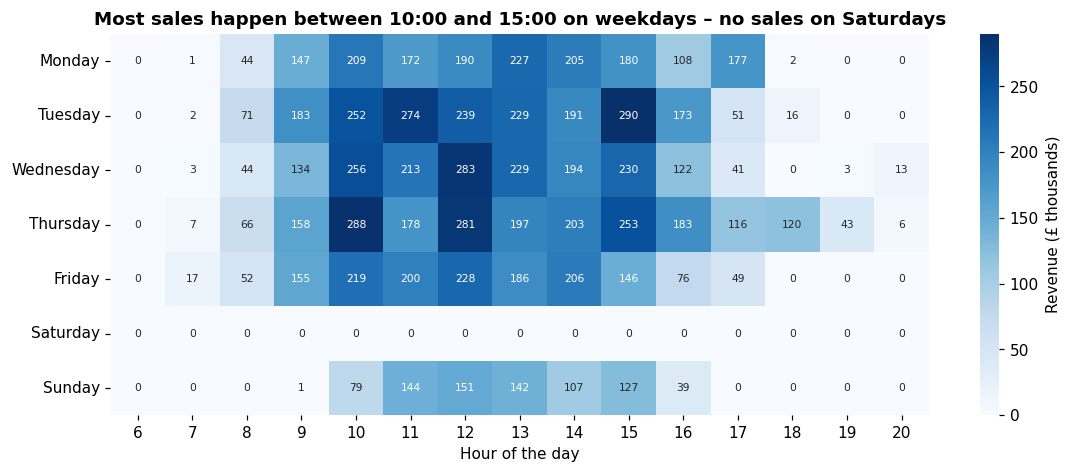

In [68]:
# SALES BY WEEKDAY AND HOUR
# pivot_table makes a table: one row per weekday, one column per hour, and in each cell the total revenue.
heat = df.pivot_table(index="Weekday", columns="Hour", values="Revenue", aggfunc="sum")

# Put the days in the normal order (otherwise they come in alphabetical order: Friday, Monday...).
# Saturday does not exist in the data, so reindex creates it with empty values -> fillna(0) shows it as 0.
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = heat.reindex(days).fillna(0) / 1000          # in £ thousands

plt.figure(figsize=(12, 4.5))
sns.heatmap(heat, cmap="Blues", annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "Revenue (£ thousands)"})
plt.title("Most sales happen between 10:00 and 15:00 on weekdays – no sales on Saturdays")
plt.xlabel("Hour of the day")
plt.ylabel("")
plt.show()

- **Goal:** find out on which days and at what times customers buy.
- **Why a heatmap:** the data is a table of 7 days × 15 hours. A table with more than 100 numbers is hard to read, but in a heatmap the darker colours show the busy times straight away. I also kept the numbers in each cell so the exact values can be read. I used one colour (blue, from light to dark) because the values only go from low to high.
- **What I see:** about **75% of sales happen between 10:00 and 15:00**. Tuesday, Wednesday and Thursday are the strongest days. There are **no sales at all on Saturday**, and Sunday is quieter and shorter. This suggests the company works with business customers on a working-week schedule. The best time for customer support is late morning and early afternoon, and the best time for system maintenance is evenings or Saturdays.